California Housing Price Prediction with Linear Regression
Beginner-friendly, end-to-end Machine Learning project

This notebook uses the uploaded california_housing.csv dataset to predict the median house value of a California district from its census-related features.
Learning objectives
By the end, you will have practised:
1. Loading and understanding a real-world dataset
2. Data quality checks and preparation
3. Exploratory data analysis (EDA)
4. Visualising distributions and relationships
5. Splitting data into training and test sets
6. Building a Linear Regression model using a preprocessing pipeline
7. Evaluating and interpreting the model
8. Checking residuals and important Linear Regression assumptions
9. Using cross-validation and saving the trained model
Important context: This dataset describes California housing districts using 1990 census data. It is useful for learning regression, but it should not be presented as a model of today's property prices.

How to use this notebook
Keep california_housing.csv in the same folder as this notebook, then run the cells from top to bottom. If the file is elsewhere, update DATA_PATH in the next section.

1. Import libraries and configure the project

In [1]:
# If any package is missing, uncomment and run this line:
# %pip install pandas numpy matplotlib seaborn scikit-learn joblib

import warnings
warnings.filterwarnings("ignore")

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
from sklearn.inspection import permutation_importance
import joblib

RANDOM_STATE = 42
TEST_SIZE = 0.20

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (8, 5)

print("Libraries imported successfully.")

Libraries imported successfully.


2. Data acquisition / generation and loading
The CSV you uploaded is the source dataset. In this project, we do not fabricate housing observations: we load the real supplied records. The train_test_split step later creates training and test subsets from these observations.

In [2]:
# The notebook first looks for the CSV beside this notebook.
# If it is not there, change DATA_PATH to the correct file location.
DATA_PATH = Path("california_housing.csv")

if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Could not find {DATA_PATH.resolve()}. "
        "Place california_housing.csv beside this notebook or update DATA_PATH."
    )

df = pd.read_csv(DATA_PATH)

print(f"Dataset loaded: {DATA_PATH.resolve()}")
print(f"Rows: {df.shape[0]:,} | Columns: {df.shape[1]}")

Dataset loaded: /content/california_housing.csv
Rows: 20,640 | Columns: 9


2.1 Preview the data

In [3]:
display(df.head())
display(df.sample(5, random_state=RANDOM_STATE))

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
20046,1.6812,25.0,4.192201,1.022284,1392.0,3.877437,36.06,-119.01,0.47700
3024,2.5313,30.0,5.039384,1.193493,1565.0,2.679795,35.14,-119.46,0.45800
15663,3.4801,52.0,3.977155,1.185877,1310.0,1.360332,37.80,-122.44,5.00001
20484,5.7376,17.0,6.163636,1.020202,1705.0,3.444444,34.28,-118.72,2.18600
9814,3.7250,34.0,5.492991,1.028037,1063.0,2.483645,36.62,-121.93,2.78000


3. Understand the dataset

In [4]:
print("Column names:")
print(df.columns.tolist())

print("\\nData types and non-null counts:")
df.info()

print("\\nSummary statistics:")
display(df.describe().T)

Column names:
['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude', 'MedHouseVal']
\nData types and non-null counts:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   MedInc       20640 non-null  float64
 1   HouseAge     20640 non-null  float64
 2   AveRooms     20640 non-null  float64
 3   AveBedrms    20640 non-null  float64
 4   Population   20640 non-null  float64
 5   AveOccup     20640 non-null  float64
 6   Latitude     20640 non-null  float64
 7   Longitude    20640 non-null  float64
 8   MedHouseVal  20640 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB
\nSummary statistics:


,count,mean,std,min,25%,50%,75%,max
MedInc,20640.0,3.870671,1.899822,0.499900,2.563400,3.534800,4.743250,15.000100
HouseAge,20640.0,28.639486,12.585558,1.000000,18.000000,29.000000,37.000000,52.000000
AveRooms,20640.0,5.429000,2.474173,0.846154,4.440716,5.229129,6.052381,141.909091
AveBedrms,20640.0,1.096675,0.473911,0.333333,1.006079,1.048780,1.099526,34.066667
Population,20640.0,1425.476744,1132.462122,3.000000,787.000000,1166.000000,1725.000000,35682.000000
AveOccup,20640.0,3.070655,10.386050,0.692308,2.429741,2.818116,3.282261,1243.333333
Latitude,20640.0,35.631861,2.135952,32.540000,33.930000,34.260000,37.710000,41.950000
Longitude,20640.0,-119.569704,2.003532,-124.350000,-121.800000,-118.490000,-118.010000,-114.310000
MedHouseVal,20640.0,2.068558,1.153956,0.149990,1.196000,1.797000,2.647250,5.000010


3.1 Understand the target and features
The target column is MedHouseVal, the median house value. Its values are expressed in units of $100,000 (for example, 2.0 represents $200,000).

The remaining eight columns are input features.

In [5]:
TARGET = "MedHouseVal"

if TARGET not in df.columns:
    raise ValueError(f"Expected target column '{TARGET}' was not found.")

X = df.drop(columns=[TARGET])
y = df[TARGET]

print("Feature columns:", X.columns.tolist())
print("Target:", TARGET)
print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)

Feature columns: ['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude']
Target: MedHouseVal
Feature matrix shape: (20640, 8)
Target shape: (20640,)


4. Data quality checks and preparation

4.1 Handle data quality issues
The uploaded file contains 20,640 rows and 9 numeric columns, with no missing values. The cell below is written defensively: it removes exact duplicate rows if any exist and checks that all model columns are numeric and finite.

We do not remove outliers automatically. Unusually large values can be genuine characteristics of a district; first inspect them and understand their impact.

In [6]:
# Work on a copy so the original loaded DataFrame remains unchanged.
data = df.copy()

# Remove exact duplicate records, if present.
data = data.drop_duplicates().copy()

# Ensure all columns used in this regression are numeric.
non_numeric_columns = data.select_dtypes(exclude=np.number).columns.tolist()
if non_numeric_columns:
    raise TypeError(f"Non-numeric columns found: {non_numeric_columns}")

# Replace +/- infinity with missing values, then remove affected rows.
data = data.replace([np.inf, -np.inf], np.nan)
data = data.dropna(subset=list(data.columns)).copy()

X = data.drop(columns=[TARGET])
y = data[TARGET]

print(f"Rows after basic cleaning: {len(data):,}")
print(f"Remaining missing values: {data.isna().sum().sum()}")

Rows after basic cleaning: 20,640
Remaining missing values: 0


5. Exploratory Data Analysis (EDA)


Markdown cell 17
Cell 17 of 66

EDA helps us understand the data before fitting a model. We will inspect distributions, summary statistics, relationships and possible outliers.


5.1 Target variable distribution
Cell 18 of 66

5.1 Target variable distribution

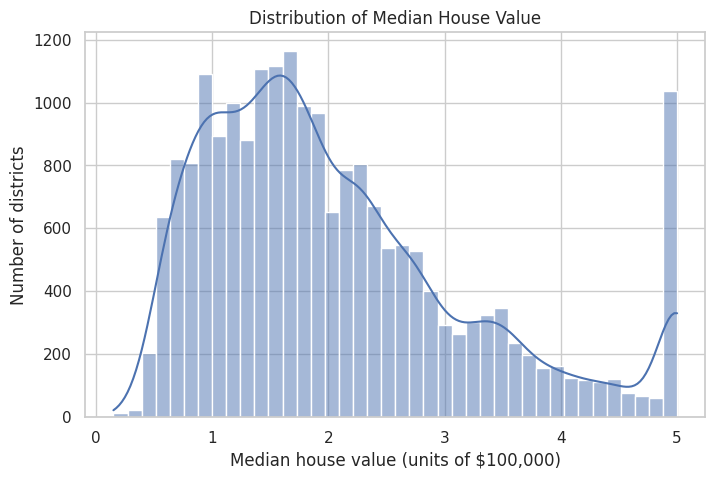

count    20640.000000
mean         2.068558
std          1.153956
min          0.149990
25%          1.196000
50%          1.797000
75%          2.647250
max          5.000010
Name: MedHouseVal, dtype: float64


In [7]:
fig, ax = plt.subplots(figsize=(8, 5))
sns.histplot(data[TARGET], bins=40, kde=True, ax=ax)
ax.set_title("Distribution of Median House Value")
ax.set_xlabel("Median house value (units of $100,000)")
ax.set_ylabel("Number of districts")
plt.show()

print(data[TARGET].describe())

5.2 Feature distributions

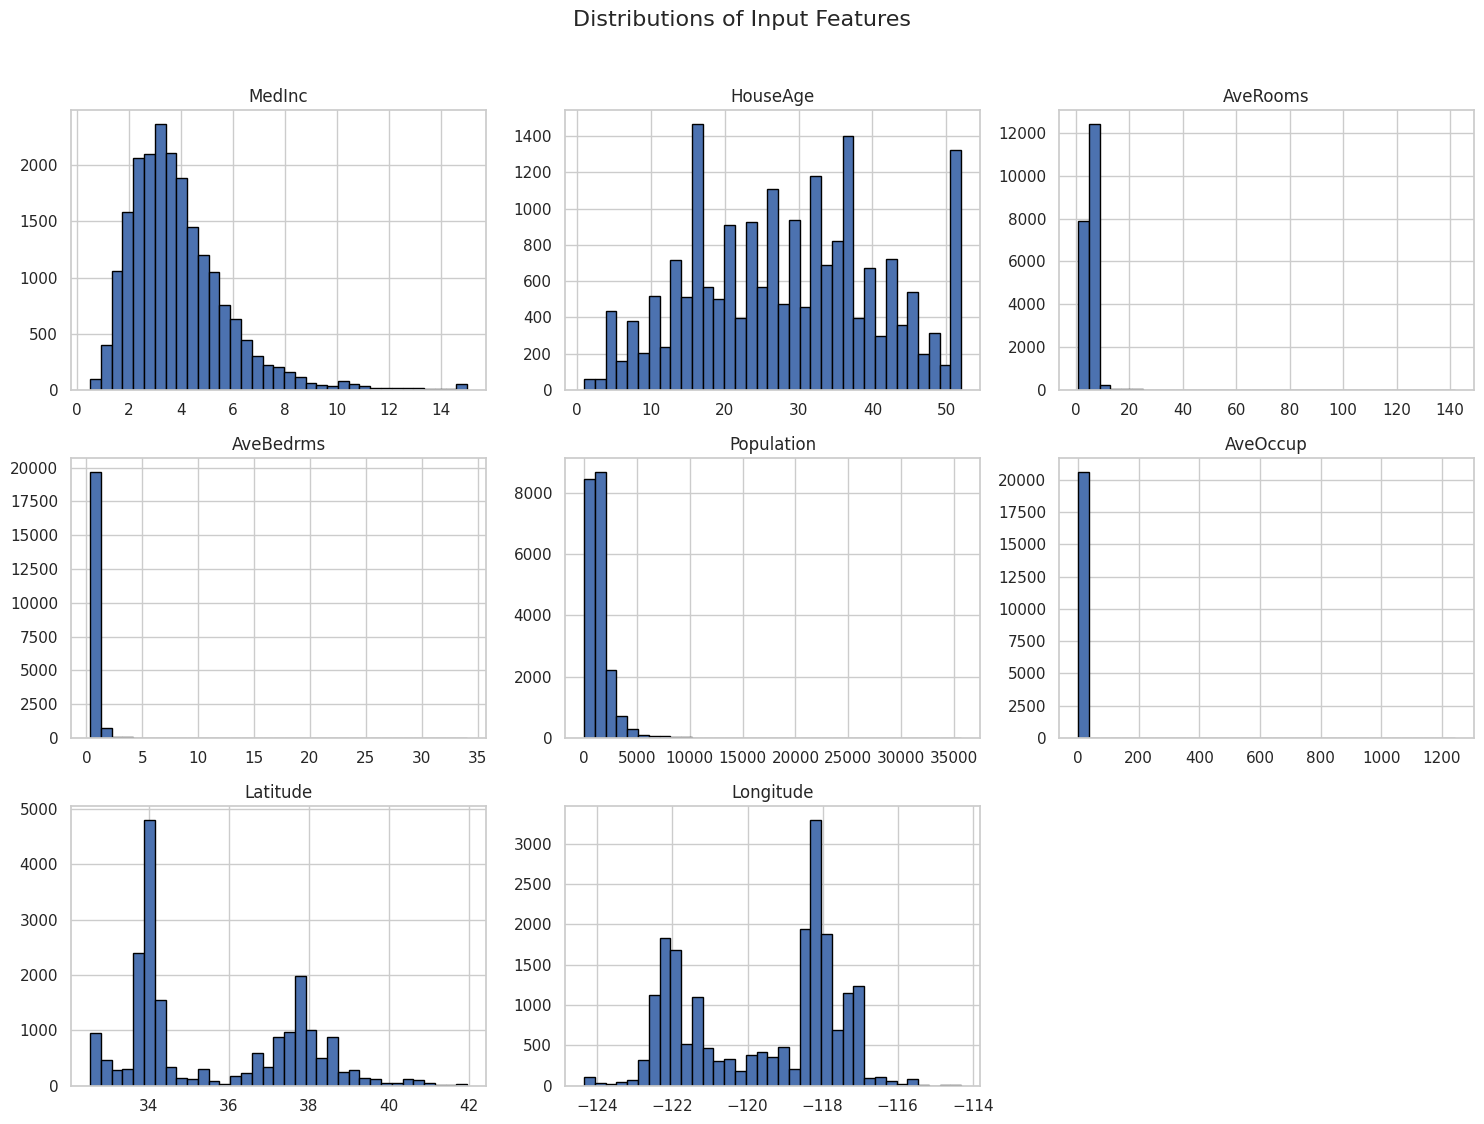

In [8]:
data.drop(columns=[TARGET]).hist(
    bins=35, figsize=(15, 11), edgecolor="black"
)
plt.suptitle("Distributions of Input Features", y=1.02, fontsize=16)
plt.tight_layout()
plt.show()

5.3 Correlation analysis

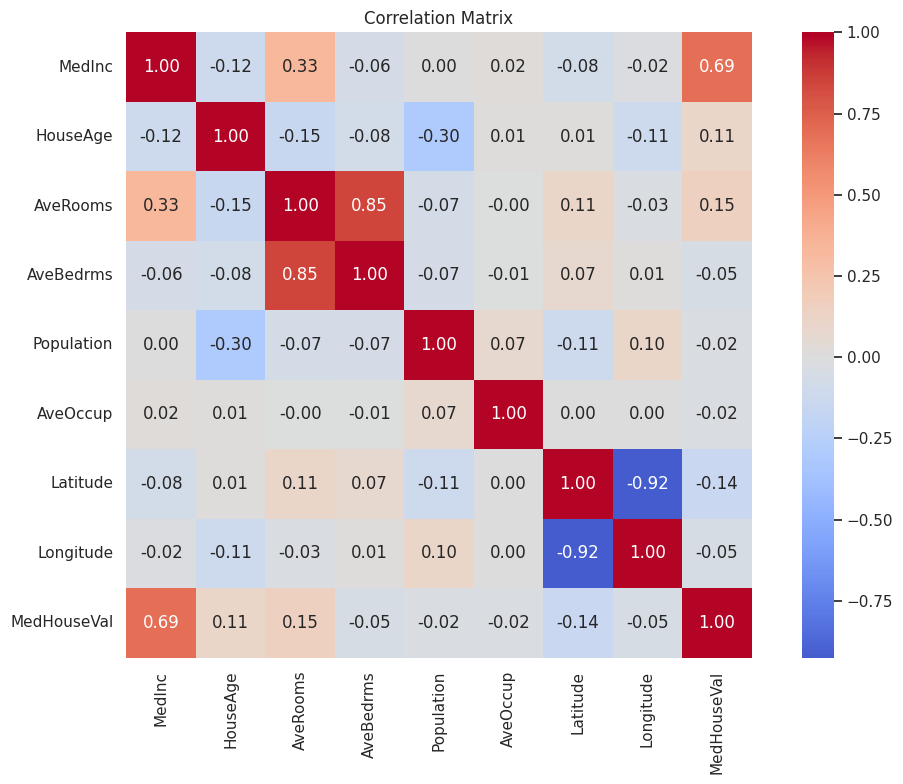

Correlation of each feature with the target:


,correlation_with_target
MedInc,0.688075
AveRooms,0.151948
Latitude,-0.144160
HouseAge,0.105623
AveBedrms,-0.046701
Longitude,-0.045967
Population,-0.024650
AveOccup,-0.023737


In [9]:
correlation = data.corr(numeric_only=True)

plt.figure(figsize=(11, 8))
sns.heatmap(
    correlation, annot=True, fmt=".2f",
    cmap="coolwarm", center=0, square=True
)
plt.title("Correlation Matrix")
plt.tight_layout()
plt.show()

print("Correlation of each feature with the target:")
display(correlation[TARGET].drop(TARGET).sort_values(
    key=lambda values: values.abs(), ascending=False
).to_frame("correlation_with_target"))

5.4 Feature versus target relationships

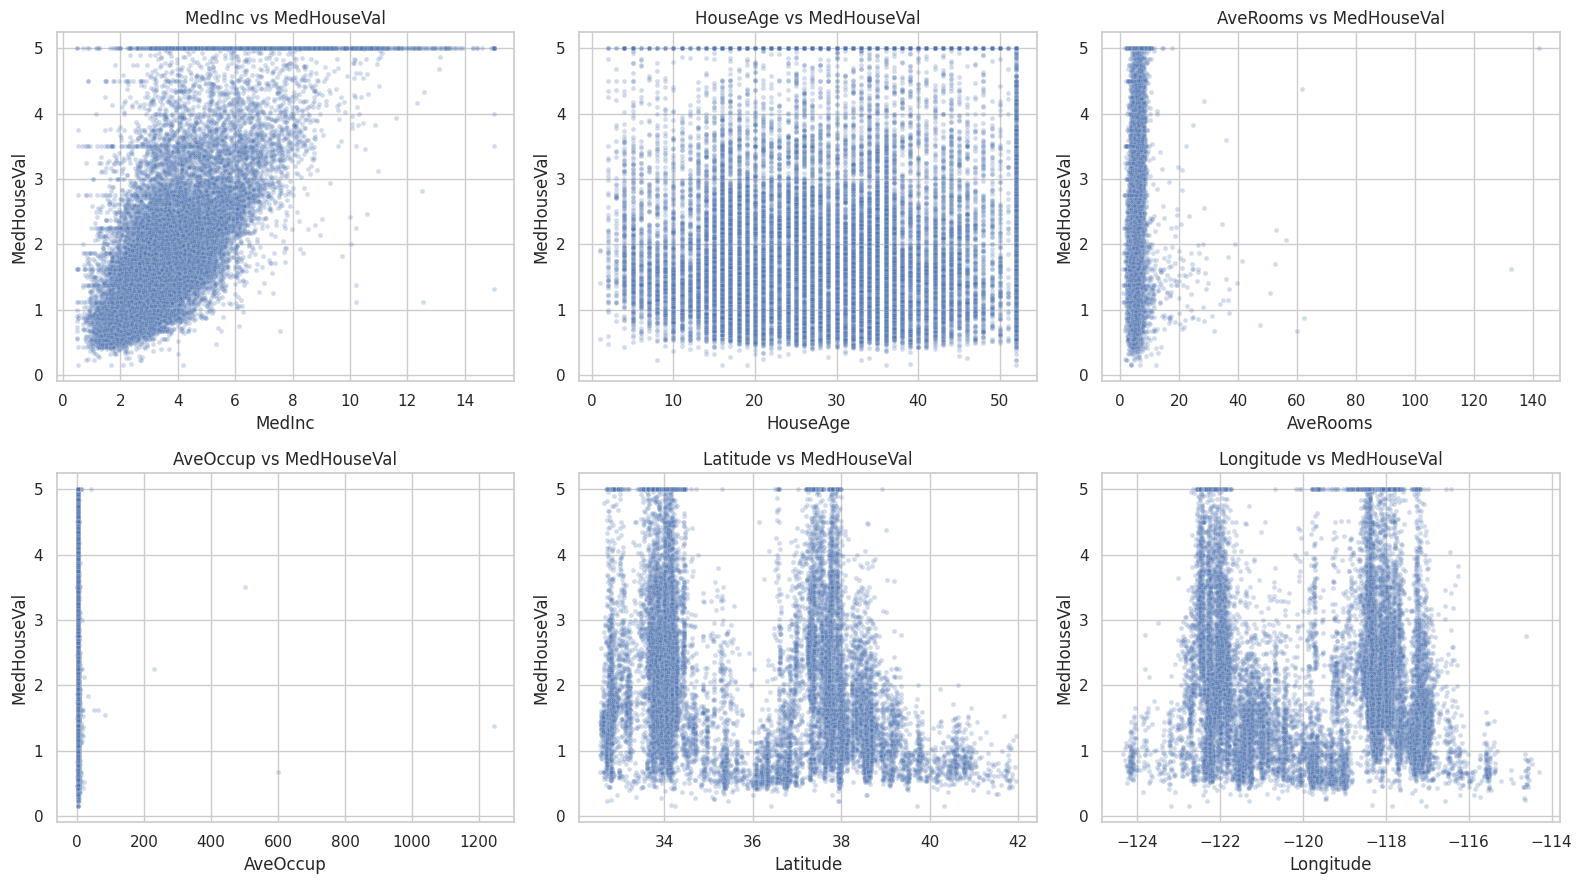

In [10]:
# Scatter plots help reveal direction, spread and non-linear patterns.
features_to_plot = ["MedInc", "HouseAge", "AveRooms", "AveOccup",
                    "Latitude", "Longitude"]

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for feature, ax in zip(features_to_plot, axes.flat):
    sns.scatterplot(
        data=data, x=feature, y=TARGET,
        alpha=0.25, s=12, ax=ax
    )
    ax.set_title(f"{feature} vs {TARGET}")
plt.tight_layout()
plt.show()

5.5 Inspect possible outliers with boxplots

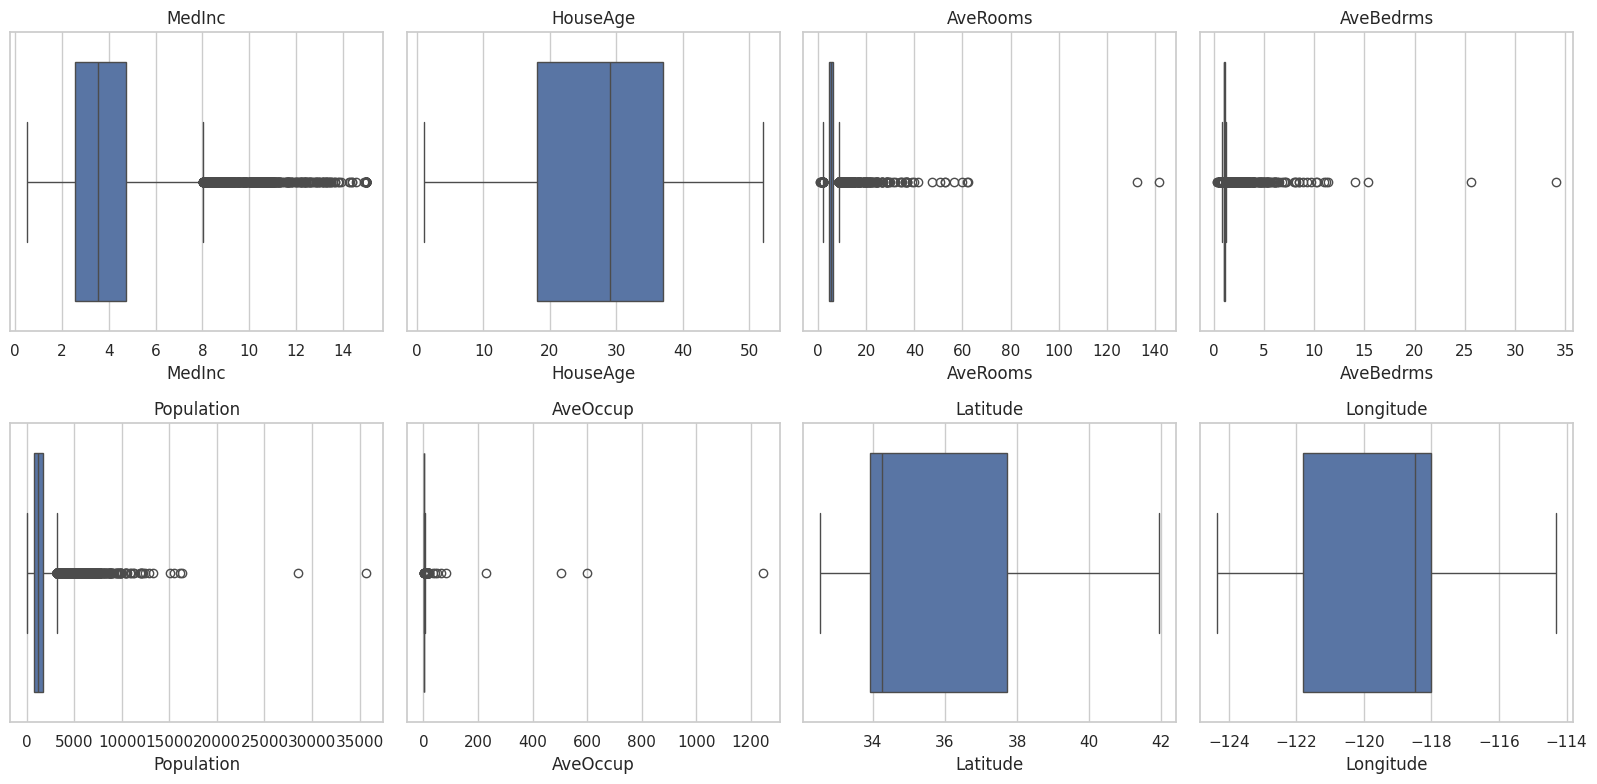

Note: a boxplot flags unusual values; it does not prove that they are errors.


In [11]:
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for feature, ax in zip(X.columns, axes.flat):
    sns.boxplot(x=data[feature], ax=ax)
    ax.set_title(feature)
plt.tight_layout()
plt.show()

print("Note: a boxplot flags unusual values; it does not prove that they are errors.")

6. Prepare features and split the data
We separate the predictors (X) from the target (y), then split into:
- 80% training data: used to learn model coefficients.
- 20% test data: held back until final evaluation.
We split before fitting the scaler. The pipeline will fit scaling only on the training data, preventing information from the test set leaking into training.

In [12]:
X = data.drop(columns=[TARGET])
y = data[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE
)

print("Training feature shape:", X_train.shape)
print("Testing feature shape:", X_test.shape)
print("Training target shape:", y_train.shape)
print("Testing target shape:", y_test.shape)

Training feature shape: (16512, 8)
Testing feature shape: (4128, 8)
Training target shape: (16512,)
Testing target shape: (4128,)


6.1 Why scale the features?
The input columns use different units and ranges (income, population, latitude, etc.). StandardScaler transforms each feature using the training-set mean and standard deviation. Scaling is not strictly required for ordinary least squares predictions, but it makes coefficient magnitudes easier to compare cautiously and is useful for a consistent preprocessing workflow.

The scaler is included inside a Pipeline, so it is fitted on training data only.


7. Build and train the Linear Regression model
Cell 31 of 66



Linear Regression estimates a relationship between the input features and a numeric target.

In this multiple-feature project, the model predicts the target using all eight features. It learns an intercept and one coefficient per feature by minimising the sum of squared residuals.

In [13]:
# Build a pipeline: scale features, then fit Linear Regression.
linear_regression_model = Pipeline(steps=[
    ("scaler", StandardScaler()),
    ("regressor", LinearRegression())
])

# Train the model using training data only.
linear_regression_model.fit(X_train, y_train)

print("Linear Regression model trained successfully.")

Linear Regression model trained successfully.


7.1 Generate predictions

In [14]:
y_train_pred = linear_regression_model.predict(X_train)
y_test_pred = linear_regression_model.predict(X_test)

predictions = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": y_test_pred,
    "Residual": y_test.values - y_test_pred
})
display(predictions.head(10))

,Actual,Predicted,Residual
0,0.47700,0.719123,-0.242123
1,0.45800,1.764017,-1.306017
2,5.00001,2.709659,2.290351
3,2.18600,2.838926,-0.652926
4,2.78000,2.604657,0.175343
5,1.58700,2.011754,-0.424754
6,1.98200,2.645500,-0.663500
7,1.57500,2.168755,-0.593755
8,3.40000,2.740746,0.659254
9,4.46600,3.915615,0.550385


8. Model evaluation


Markdown cell 37
Cell 37 of 66

We evaluate predictions on the held-out test set. These metrics answer different questions:
- MAE: average absolute prediction error, in target units.
- MSE: average squared error; larger errors receive more penalty.
- RMSE: square root of MSE, in the same units as the target.
- R²: proportion of target variation explained by the model relative to predicting the test-set mean. It can be negative if the model performs worse than that baseline.

In [15]:
def regression_metrics(y_true, y_pred):
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "MSE": mean_squared_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "R2": r2_score(y_true, y_pred)
    }

train_metrics = regression_metrics(y_train, y_train_pred)
test_metrics = regression_metrics(y_test, y_test_pred)

metrics_df = pd.DataFrame(
    [train_metrics, test_metrics],
    index=["Training", "Testing"]
)

display(metrics_df.round(4))

,MAE,MSE,RMSE,R2
Training,0.5286,0.5179,0.7197,0.6126
Testing,0.5332,0.5559,0.7456,0.5758


8.1 Interpret the error in dollars
The target is measured in units of $100,000. Multiply MAE and RMSE by 100,000 to express them in dollars. These are average error summaries, not guarantees about an individual prediction.

In [16]:
mae_dollars = test_metrics["MAE"] * 100_000
rmse_dollars = test_metrics["RMSE"] * 100_000

print(f"Test MAE:  ${mae_dollars:,.0f}")
print(f"Test RMSE: ${rmse_dollars:,.0f}")
print(f"Test R²:   {test_metrics['R2']:.4f}")

Test MAE:  $53,320
Test RMSE: $74,558
Test R²:   0.5758


9. Model evaluation visualisations

9.1 Actual versus predicted values

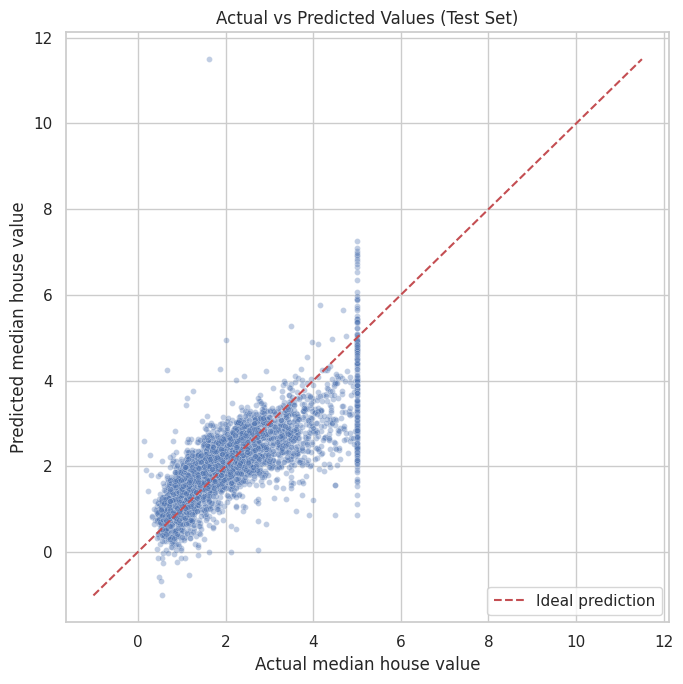

In [17]:
plt.figure(figsize=(7, 7))
sns.scatterplot(x=y_test, y=y_test_pred, alpha=0.35, s=18)
min_value = min(y_test.min(), y_test_pred.min())
max_value = max(y_test.max(), y_test_pred.max())
plt.plot([min_value, max_value], [min_value, max_value],
         "r--", label="Ideal prediction")
plt.xlabel("Actual median house value")
plt.ylabel("Predicted median house value")
plt.title("Actual vs Predicted Values (Test Set)")
plt.legend()
plt.tight_layout()
plt.show()

How to read this plot: points close to the diagonal represent more accurate predictions. A wide vertical spread indicates larger errors. Patterns or clusters can indicate that the model behaves differently for different value ranges or regions.

9.2 Residual distribution

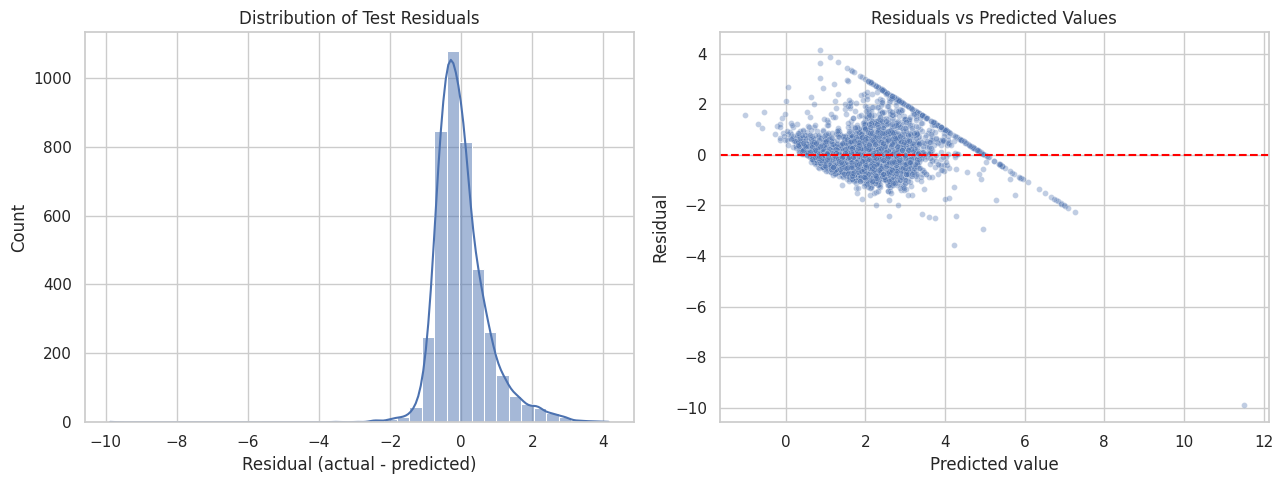

In [18]:
residuals = y_test - y_test_pred

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.histplot(residuals, bins=40, kde=True, ax=axes[0])
axes[0].set_title("Distribution of Test Residuals")
axes[0].set_xlabel("Residual (actual - predicted)")

sns.scatterplot(x=y_test_pred, y=residuals, alpha=0.35, s=18, ax=axes[1])
axes[1].axhline(0, color="red", linestyle="--")
axes[1].set_title("Residuals vs Predicted Values")
axes[1].set_xlabel("Predicted value")
axes[1].set_ylabel("Residual")
plt.tight_layout()
plt.show()

Residual interpretation:
- Residual = actual value − predicted value.
- Positive residual: the model underpredicted.
- Negative residual: the model overpredicted.
- Ideally, residuals are centred around zero with no obvious pattern.
- A funnel shape or curve can suggest non-constant error variance or a missing non-linear relationship.

9.3 Q-Q plot for residual normality (diagnostic)

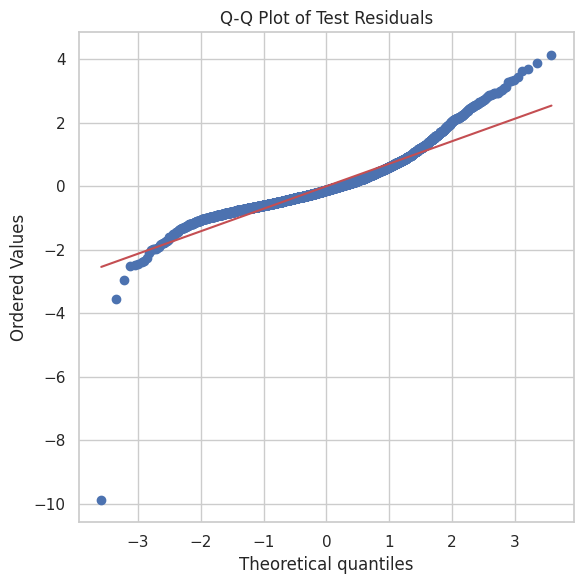

In [19]:
from scipy import stats

plt.figure(figsize=(6, 6))
stats.probplot(residuals, dist="norm", plot=plt)
plt.title("Q-Q Plot of Test Residuals")
plt.tight_layout()
plt.show()

A Q-Q plot compares residual quantiles with theoretical normal quantiles. Strong departures from the line suggest residuals are not normally distributed. Normal residuals are mainly relevant for classical statistical inference; prediction can still be useful when residuals are not perfectly normal.

10. Interpret the learned coefficients


Markdown cell 52
Cell 52 of 66

The fitted model uses standardised features. Therefore, each coefficient describes the expected change in the predicted target for a one-standard-deviation increase in that feature, holding the other features constant.

Because the inputs are correlated and measured at district level, coefficients should be interpreted as model associations, not proof of cause and effect.

In [20]:
scaler = linear_regression_model.named_steps["scaler"]
regressor = linear_regression_model.named_steps["regressor"]

coefficients = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient (standardised feature)": regressor.coef_
})
coefficients["Absolute coefficient"] = coefficients[
    "Coefficient (standardised feature)"
].abs()
coefficients = coefficients.sort_values(
    "Absolute coefficient", ascending=False
)

display(coefficients)

,Feature,Coefficient (standardised feature),Absolute coefficient
6,Latitude,-0.896929,0.896929
7,Longitude,-0.869842,0.869842
0,MedInc,0.854383,0.854383
3,AveBedrms,0.339259,0.339259
2,AveRooms,-0.294410,0.294410
1,HouseAge,0.122546,0.122546
5,AveOccup,-0.040829,0.040829
4,Population,-0.002308,0.002308


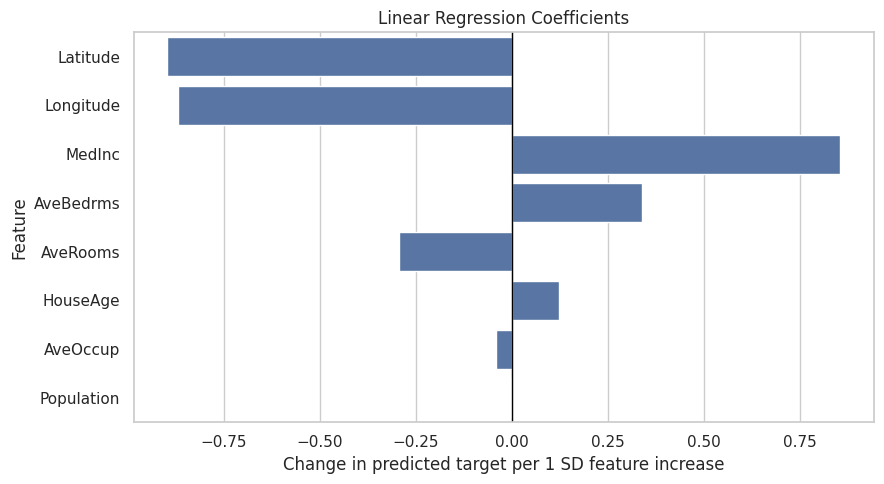

In [21]:
plt.figure(figsize=(9, 5))
sns.barplot(
    data=coefficients,
    x="Coefficient (standardised feature)",
    y="Feature"
)
plt.axvline(0, color="black", linewidth=1)
plt.title("Linear Regression Coefficients")
plt.xlabel("Change in predicted target per 1 SD feature increase")
plt.tight_layout()
plt.show()

10.1 Permutation feature importance (optional interpretation tool)


Markdown cell 56
Cell 56 of 66

Permutation importance measures how much the test score falls when one feature is shuffled. It can be easier to interpret than raw coefficient size when feature scales differ, but correlated features can share or mask importance.

,Feature,Importance mean,Importance std
6,Latitude,1.218143,0.025708
7,Longitude,1.147945,0.027289
0,MedInc,1.038924,0.022817
3,AveBedrms,0.264952,0.008732
2,AveRooms,0.234098,0.007538
1,HouseAge,0.022112,0.002420
5,AveOccup,0.001017,0.000174
4,Population,0.000004,0.000034


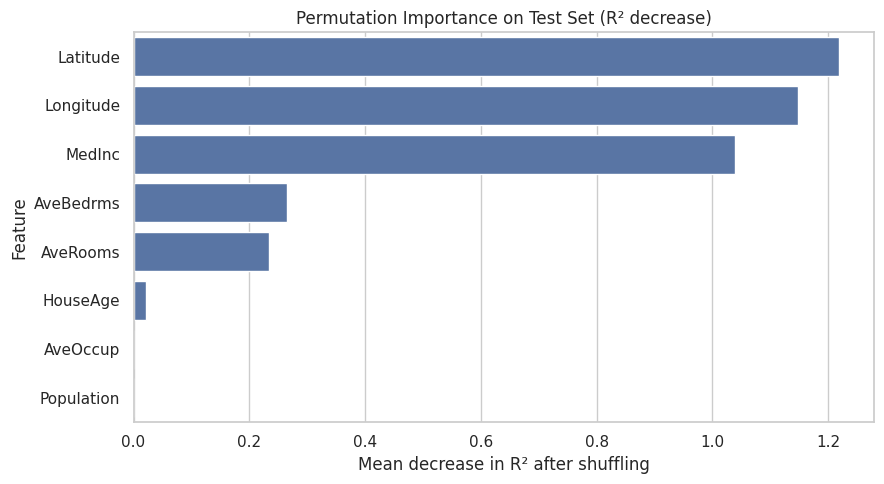

In [22]:
perm_result = permutation_importance(
    linear_regression_model,
    X_test,
    y_test,
    n_repeats=10,
    random_state=RANDOM_STATE,
    scoring="r2"
)

permutation_df = pd.DataFrame({
    "Feature": X.columns,
    "Importance mean": perm_result.importances_mean,
    "Importance std": perm_result.importances_std
}).sort_values("Importance mean", ascending=False)

display(permutation_df)

plt.figure(figsize=(9, 5))
sns.barplot(data=permutation_df, x="Importance mean", y="Feature")
plt.title("Permutation Importance on Test Set (R² decrease)")
plt.xlabel("Mean decrease in R² after shuffling")
plt.tight_layout()
plt.show()

11. Cross-validation


Markdown cell 59
Cell 59 of 66

A single train/test split can produce a result that depends on which rows happened to be selected. K-fold cross-validation repeatedly trains and evaluates the pipeline on different partitions of the training data.

We use only the training set for cross-validation. The test set remains reserved for the final evaluation.

In [23]:
cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_r2_scores = cross_val_score(
    linear_regression_model,
    X_train,
    y_train,
    cv=cv,
    scoring="r2"
)

print("R² scores for each fold:", np.round(cv_r2_scores, 4))
print(f"Mean CV R²: {cv_r2_scores.mean():.4f}")
print(f"Standard deviation: {cv_r2_scores.std():.4f}")

R² scores for each fold: [0.6097 0.6041 0.6354 0.6008 0.6073]
Mean CV R²: 0.6115
Standard deviation: 0.0124


12. Make a prediction for a new example


Markdown cell 62
Cell 62 of 66

The example below uses the first test row as an illustration. For a real new prediction, provide values for all eight features using the same units and definitions as the training data.

In [24]:
example_house = X_test.iloc[[0]]
example_prediction = linear_regression_model.predict(example_house)[0]

print("Input features:")
display(example_house)
print(f"Predicted median house value: {example_prediction:.3f} (units of $100,000)")
print(f"Approximate dollar value: ${example_prediction * 100_000:,.0f}")

Input features:


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude
20046,1.6812,25.0,4.192201,1.022284,1392.0,3.877437,36.06,-119.01


Predicted median house value: 0.719 (units of $100,000)
Approximate dollar value: $71,912
